In [8]:
# Single sample per met to prevents repeated sampling from inflating site counts
# Step 6 (NO CNV MASKING):
# Define universe as ALL autosomal bins present in the ratio matrix (chr1–chr22)

import os
import pandas as pd

RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/no_cnv_masking_universe"
os.makedirs(OUTDIR, exist_ok=True)

CHR_ORDER = [f"chr{i}" for i in range(1, 23)]

# Load ratio matrix (samples x bins)
df = pd.read_csv(RATIO_FILE)
df = df.set_index("Unnamed: 0")
df.index.name = "sample"

samples = df.index.tolist()
bin_cols = df.columns.astype(str).tolist()

print("Samples:", len(samples))
print("Total bins in ratio file:", len(bin_cols))

# Keep only chr1–chr22 bins
auto_bins = [b for b in bin_cols if b.split("_")[0] in CHR_ORDER]

print("Autosomal (chr1–chr22) bins:", len(auto_bins))
print("Example autosomal bins:", auto_bins[:3])

# Save universe list (optional, but useful for reproducibility)
universe_txt = os.path.join(OUTDIR, "universe_all_autosomal_bins.txt")
with open(universe_txt, "w") as f:
    f.write("\n".join(auto_bins) + "\n")

print("Wrote universe to:", universe_txt)
print("OUTDIR:", OUTDIR)

Samples: 262
Total bins in ratio file: 27520
Autosomal (chr1–chr22) bins: 26175
Example autosomal bins: ['chr3_165000000_165100000', 'chr8_112900000_113000000', 'chr13_55700000_55800000']
Wrote universe to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/no_cnv_masking_universe/universe_all_autosomal_bins.txt
OUTDIR: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/no_cnv_masking_universe


Top 3 metastatic sites: ['liver', 'bone', 'brain']
Universe (no CNV masking): 26175 bins


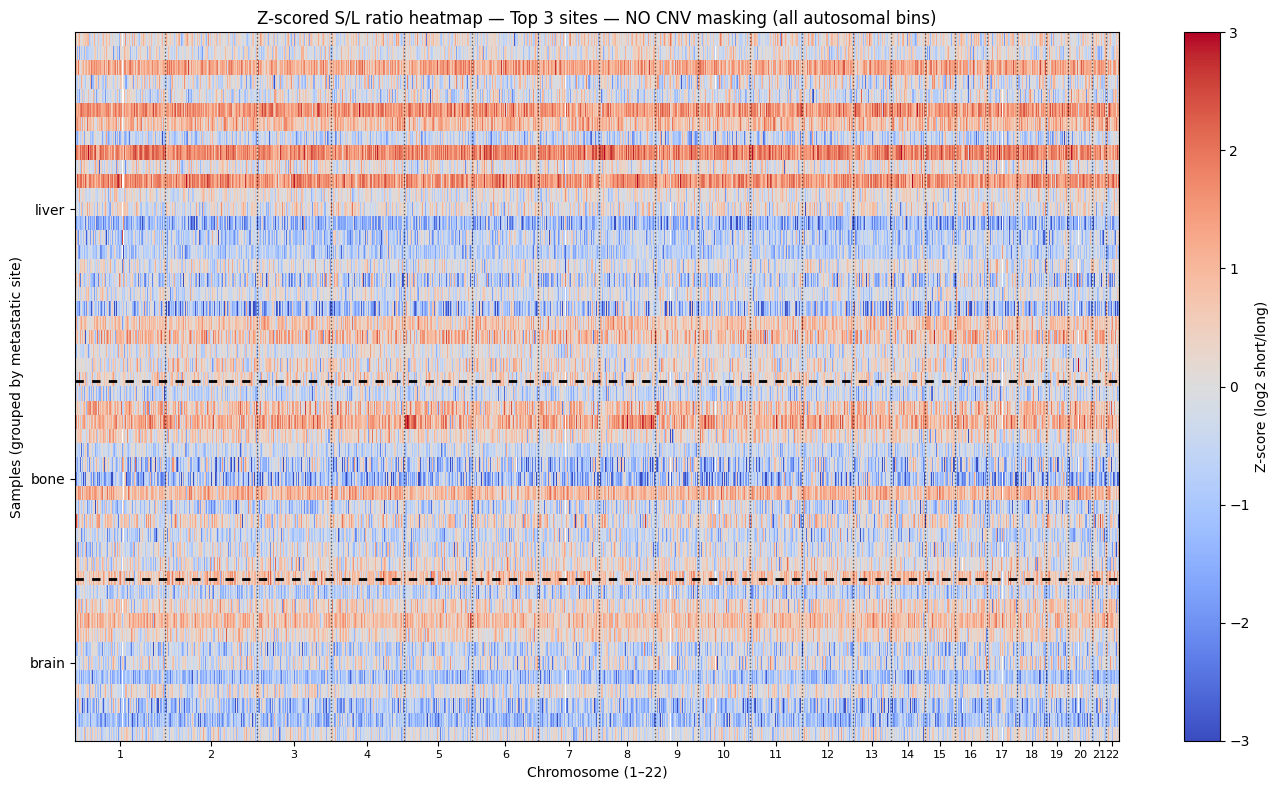

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps_no_cnv_masking/zscore_heatmap_top3sites_no_cnv_masking_chr.png


In [9]:
# Z-scored S/L heatmap using ALL autosomal bins (chr1–chr22) — NO CNV MASKING

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Paths
# -----------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
META_FILE  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps_no_cnv_masking"
os.makedirs(OUTDIR, exist_ok=True)

CHR_ORDER = [f"chr{i}" for i in range(1, 23)]

# -----------------------------
# Load S/L ratio matrix
# -----------------------------
ratio = pd.read_csv(RATIO_FILE)
ratio = ratio.set_index("Unnamed: 0")
ratio.index.name = "sample"

# log2 transform (match your previous behavior)
ratio = np.log2(ratio.replace(0, np.nan))

# -----------------------------
# Load metastatic site metadata
# -----------------------------
meta = pd.read_csv(META_FILE)
meta["id"] = meta["id"].astype(str)
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.lower()

meta = meta[meta["id"].isin(ratio.index)].copy()
meta = meta.set_index("id")

# -----------------------------
# Determine TOP 3 sites once
# -----------------------------
site_counts = meta["metastatic_sites"].value_counts()
top3_sites = site_counts.head(3).index.tolist()
print("Top 3 metastatic sites:", top3_sites)

meta_top = meta[meta["metastatic_sites"].isin(top3_sites)].copy()
site_order = top3_sites

# -----------------------------
# Z-score per bin
# -----------------------------
def zscore_by_bin(df):
    mu = df.mean(axis=0, skipna=True)
    sd = df.std(axis=0, skipna=True)
    return (df - mu) / sd

# -----------------------------
# Bin parsing + genome ordering
# -----------------------------
def parse_bin(bin_id: str):
    chrom, start, end = bin_id.split("_")
    return chrom, int(start), int(end)

def genome_sort_bins(bin_list):
    rows = []
    for b in bin_list:
        chrom, start, end = parse_bin(b)
        if chrom in CHR_ORDER:
            chrom_num = int(chrom.replace("chr", ""))
            rows.append((chrom_num, start, b))
    rows.sort()
    return [b for _, _, b in rows]

def chr_ticks_and_boundaries(ordered_bins):
    chroms = np.array([b.split("_")[0] for b in ordered_bins])
    chr_mid = {}
    boundaries = []
    for chrom in CHR_ORDER:
        idx = np.where(chroms == chrom)[0]
        if len(idx) == 0:
            continue
        s = idx.min()
        e = idx.max()
        chr_mid[chrom] = (s + e) / 2
        boundaries.append(e + 0.5)
    return chr_mid, boundaries

# -----------------------------
# Universe = ALL autosomal bins present
# -----------------------------
bins = [b for b in ratio.columns.astype(str).tolist() if b.split("_")[0] in CHR_ORDER]
print("Universe (no CNV masking):", len(bins), "bins")

bins_sorted = genome_sort_bins(bins)

# Subset matrix to TOP 3 site samples only
X = ratio[bins_sorted].copy()
X = X.loc[meta_top.index]

# Z-score AFTER top3 subsetting (same as your prior logic)
Z = zscore_by_bin(X)

# Order samples by site order
meta_ord = meta_top.copy()
meta_ord["metastatic_sites"] = pd.Categorical(
    meta_ord["metastatic_sites"], categories=site_order, ordered=True
)
meta_ord = meta_ord.sort_values("metastatic_sites")
Z = Z.loc[meta_ord.index]

# Boundaries between site blocks (y separators)
site_sizes = (
    meta_ord["metastatic_sites"]
    .value_counts()
    .reindex(site_order)
    .fillna(0)
    .astype(int)
)
y_boundaries = np.cumsum(site_sizes.values)[:-1]

# Chromosome ticks + x boundaries
chr_mid, x_boundaries = chr_ticks_and_boundaries(bins_sorted)

# -----------------------------
# Plot heatmap
# -----------------------------
plt.figure(figsize=(14, 8))
plt.imshow(
    Z.values,
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=-3,
    vmax=3
)
plt.colorbar(label="Z-score (log2 short/long)")

for b in y_boundaries:
    plt.axhline(b + 0.1, color="black", linewidth=2.0, linestyle=(0, (3, 3)))

for xb in x_boundaries:
    plt.axvline(xb, color="black", linewidth=1.0, linestyle=":", alpha=0.6)

# Y labels at block midpoints
yticks, ylabels = [], []
start = 0
for site in site_order:
    n = (meta_ord["metastatic_sites"] == site).sum()
    if n > 0:
        yticks.append(start + n / 2)
        ylabels.append(site)
        start += n
plt.yticks(yticks, ylabels)

# X labels at chr midpoints
xticks = list(chr_mid.values())
xlabels = [c.replace("chr", "") for c in chr_mid.keys()]
plt.xticks(xticks, xlabels, fontsize=8)
plt.xlabel("Chromosome (1–22)")
plt.ylabel("Samples (grouped by metastatic site)")

plt.title("Z-scored S/L ratio heatmap — Top 3 sites — NO CNV masking (all autosomal bins)")

outpng = os.path.join(OUTDIR, "zscore_heatmap_top3sites_no_cnv_masking_chr.png")
plt.tight_layout()
plt.savefig(outpng, dpi=200)
plt.show()
plt.close()

print("Saved:", outpng)

In [10]:
# Computes η² per bin (top-3 sites only) — NO CNV MASKING
# Universe = all autosomal bins (chr1–chr22) present in ratio matrix

import re
import numpy as np
import pandas as pd
import os

# ============================
# PATHS
# ============================
RATIO_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
META_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking"
os.makedirs(OUTDIR, exist_ok=True)

OUT_PREFIX = "eta2_fragmentation_top3sites_no_cnv_masking"

TOP_N_LIST = [500, 1000]

SAMPLE_COL = "id"
SITE_COL   = "metastatic_sites"

CHR_ORDER = [f"chr{i}" for i in range(1, 23)]


def eta2_oneway(y: np.ndarray, groups: np.ndarray) -> float:
    """Eta-squared for one-way ANOVA: SS_between / SS_total."""
    mask = ~np.isnan(y)
    y = y[mask]
    g = groups[mask]

    if y.size < 3:
        return np.nan

    y_bar = y.mean()
    ss_total = ((y - y_bar) ** 2).sum()
    if ss_total == 0:
        return 0.0

    ss_between = 0.0
    for lvl in np.unique(g):
        yg = y[g == lvl]
        if yg.size > 0:
            ss_between += yg.size * ((yg.mean() - y_bar) ** 2)

    return float(ss_between / ss_total)


def parse_bin_to_bed(bin_id: str):
    """
    Convert bin id to BED (chr, start, end).
    Expected format: chr6_95000000_95100000
    Also supports: chr6:95000000-95100000
    """
    s = str(bin_id).strip()

    m = re.match(r"^(chr[0-9XYM]+)_(\d+)_(\d+)$", s)
    if m:
        return m.group(1), int(m.group(2)), int(m.group(3))

    m = re.match(r"^(chr[0-9XYM]+):(\d+)-(\d+)$", s)
    if m:
        return m.group(1), int(m.group(2)), int(m.group(3))

    raise ValueError(f"Unrecognized bin format: {bin_id}")


def write_bed(bin_list, out_bed):
    rows = [parse_bin_to_bed(b) for b in bin_list]
    bed = pd.DataFrame(rows, columns=["chr", "start", "end"])
    bed.to_csv(out_bed, sep="\t", header=False, index=False)


# ============================
# Load ratio matrix
# ============================
ratio_raw = pd.read_csv(RATIO_CSV, index_col=0)   # samples x bins
ratio_raw.index = ratio_raw.index.astype(str).str.strip()

print("Loaded ratio_raw (samples x bins):", ratio_raw.shape)

# Drop duplicate sample IDs in ratio, keep first
dup_ratio = ratio_raw.index.duplicated(keep="first")
n_dup_ratio = int(dup_ratio.sum())
if n_dup_ratio > 0:
    print(f"[WARN] Duplicate sample IDs in ratio matrix: {n_dup_ratio} duplicated rows dropped")
    ratio_raw = ratio_raw.loc[~dup_ratio].copy()

print("Ratio after sample deduplication:", ratio_raw.shape)

# log2 transform so output column names '*_log2SL' are correct
ratio_raw = ratio_raw.replace(0, np.nan)
ratio_log2 = np.log2(ratio_raw)

# transpose to bins x samples
ratio = ratio_log2.T
ratio.index = ratio.index.astype(str)
ratio.columns = ratio.columns.astype(str)

print("Loaded ratio (bins x samples):", ratio.shape)

# Keep only well-formed autosomal bins
auto_bins = []
bad_bins = []

for b in ratio.index.tolist():
    parts = str(b).split("_")
    if len(parts) != 3:
        bad_bins.append(b)
        continue
    if parts[0] in CHR_ORDER:
        auto_bins.append(b)

ratio = ratio.loc[auto_bins].copy()
print("Autosomal bins retained:", ratio.shape[0])
print("Malformed / skipped bins:", len(bad_bins))

# ============================
# Load metadata + keep one row per current sample ID
# ============================
meta = pd.read_csv(META_CSV, dtype=str)[[SAMPLE_COL, SITE_COL]].dropna()
meta[SAMPLE_COL] = meta[SAMPLE_COL].astype(str).str.strip()
meta[SITE_COL]   = meta[SITE_COL].astype(str).str.strip().str.lower()

print("Metadata rows before cleanup:", meta.shape[0])

# Drop duplicate sample IDs in metadata, keep first
dup_meta = meta[SAMPLE_COL].duplicated(keep="first")
n_dup_meta = int(dup_meta.sum())
if n_dup_meta > 0:
    print(f"[WARN] Duplicate sample IDs in metadata: {n_dup_meta} duplicated rows dropped")
    meta = meta.loc[~dup_meta].copy()

# Keep only samples present in ratio
meta = meta[meta[SAMPLE_COL].isin(ratio.columns)].copy()

print("Metadata rows after cleanup/matching:", meta.shape[0])
print("Unique matched sample IDs:", meta[SAMPLE_COL].nunique())

# Determine top-3 sites from CURRENT cleaned metadata
top3_sites = meta[SITE_COL].value_counts().head(3).index.tolist()
meta_top3 = meta[meta[SITE_COL].isin(top3_sites)].copy()

# Preserve one sample per sample ID
samples_top3 = meta_top3[SAMPLE_COL].drop_duplicates().tolist()
ratio_top3 = ratio[samples_top3].copy()  # bins x samples

site_by_sample = meta_top3.set_index(SAMPLE_COL).loc[ratio_top3.columns, SITE_COL].values
site_counts = meta_top3[SITE_COL].value_counts()

print("\nTop 3 sites:", top3_sites)
print("Current sample counts from cleaned metadata:")
print(site_counts)
print("N samples in top3:", len(samples_top3))
print("ratio_top3 shape:", ratio_top3.shape)

# ============================
# η² across ALL autosomal bins (no CNV masking)
# ============================
arr = ratio_top3.values.astype(float)

eta2_vals = []
mean_all = []
site_means = {s: [] for s in top3_sites}

for i in range(arr.shape[0]):
    y = arr[i, :]
    eta2_vals.append(eta2_oneway(y, site_by_sample))
    mean_all.append(np.nanmean(y))
    for s in top3_sites:
        site_means[s].append(np.nanmean(y[site_by_sample == s]))

res = pd.DataFrame({
    "bin_id": ratio_top3.index,
    "eta2": eta2_vals,
    "mean_all_log2SL": mean_all,
})

for s in top3_sites:
    res[f"mean_{s}_log2SL"] = site_means[s]
    res[f"n_{s}"] = int(site_counts.get(s, 0))

res["direction_global"] = np.where(
    res["mean_all_log2SL"] > 0,
    "short_enriched",
    "long_enriched"
)

site_cols = [f"mean_{s}_log2SL" for s in top3_sites]
res["delta_maxmin"] = res[site_cols].max(axis=1) - res[site_cols].min(axis=1)

res = res.sort_values("eta2", ascending=False).reset_index(drop=True)
res["rank_eta2"] = np.arange(1, res.shape[0] + 1)

out_tsv = os.path.join(OUTDIR, f"{OUT_PREFIX}.eta2.tsv")
res.to_csv(out_tsv, sep="\t", index=False)
print("Wrote:", out_tsv)

# ============================
# LOLA BEDs (Top-N by eta2, split by direction)
# ============================
for N in TOP_N_LIST:
    topN = res.head(N).copy()

    short_set = topN[topN["direction_global"] == "short_enriched"]
    long_set  = topN[topN["direction_global"] == "long_enriched"]

    bed_short = os.path.join(OUTDIR, f"{OUT_PREFIX}.top{N}.short_enriched.bed")
    bed_long  = os.path.join(OUTDIR, f"{OUT_PREFIX}.top{N}.long_enriched.bed")

    write_bed(short_set["bin_id"].tolist(), bed_short)
    write_bed(long_set["bin_id"].tolist(), bed_long)

    print(f"Top{N}: short={short_set.shape[0]} long={long_set.shape[0]}")
    print("  Wrote:", bed_short)
    print("  Wrote:", bed_long)

print("\nDONE (NO CNV MASKING).")

Loaded ratio_raw (samples x bins): (262, 27520)
Ratio after sample deduplication: (262, 27520)
Loaded ratio (bins x samples): (27520, 262)
Autosomal bins retained: 26175
Malformed / skipped bins: 0
Metadata rows before cleanup: 80
Metadata rows after cleanup/matching: 80
Unique matched sample IDs: 80

Top 3 sites: ['liver', 'bone', 'brain']
Current sample counts from cleaned metadata:
liver    24
bone     14
brain    12
Name: metastatic_sites, dtype: int64
N samples in top3: 50
ratio_top3 shape: (26175, 50)
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/eta2_fragmentation_top3sites_no_cnv_masking.eta2.tsv
Top500: short=0 long=500
  Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/eta2_fragmentation_top3sites_no_cnv_masking.top500.short_enriched.bed
  Wrote: /ix1

In [11]:
"""
Kruskal–Wallis (KW) + Benjamini–Hochberg (BH-FDR) on Top-1000 η² bins
for NO CNV masking (all autosomal bins) across the top-3 metastatic sites.
This file keeps both raw KW p-values and BH-adjusted q-values, so we can
later filter on either kw_p or kw_q_BH.
"""

import os
import numpy as np
import pandas as pd
from scipy.stats import kruskal

# -------------------------
# Paths
# -------------------------
RATIO_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
META_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

ETA2_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/eta2_fragmentation_top3sites_no_cnv_masking.eta2.tsv"

KW_BH_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH"
OUTDIR = KW_BH_DIR
os.makedirs(KW_BH_DIR, exist_ok=True)

sites = ["liver", "brain", "bone"]

SAMPLE_COL = "id"
SITE_COL   = "metastatic_sites"

TOP_N = 1000
MIN_GROUP_N = 3
CHR_ORDER = [f"chr{i}" for i in range(1, 23)]

# Always rebuild from current metadata / current eta2 ranking
FORCE_REBUILD = True

# -------------------------
# Helpers
# -------------------------
def bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    ok = np.isfinite(p)
    if ok.sum() == 0:
        return q

    p_ok = p[ok]
    n = p_ok.size
    order = np.argsort(p_ok)
    ranked = p_ok[order]

    q_ranked = ranked * n / (np.arange(1, n + 1))
    q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
    q_ranked = np.clip(q_ranked, 0, 1)

    tmp = np.empty_like(p_ok)
    tmp[order] = q_ranked
    q[ok] = tmp
    return q


def build_kw_bh_from_eta2_no_masking(ratio_top3, site_by_sample, site_counts):
    """Build KW/BH table from current eta2 ranking and current sample set."""
    if not os.path.exists(ETA2_TSV):
        raise IOError(f"Missing η² file: {ETA2_TSV}")

    eta2 = pd.read_csv(ETA2_TSV, sep="\t", dtype={"bin_id": str})
    if "bin_id" not in eta2.columns or "eta2" not in eta2.columns:
        raise ValueError("η² file must contain columns: bin_id, eta2")

    top_bins = eta2["bin_id"].head(TOP_N).tolist()
    top_bins = [b for b in top_bins if b in ratio_top3.index]
    if len(top_bins) == 0:
        raise ValueError("Top bins list empty after intersect with current ratio_top3.")

    df = eta2[eta2["bin_id"].isin(top_bins)][["bin_id", "eta2"]].copy()

    if "rank_eta2" in eta2.columns:
        rank_map = eta2.set_index("bin_id")["rank_eta2"].to_dict()
        df["rank_eta2"] = df["bin_id"].map(rank_map)
    else:
        order_map = {b: i + 1 for i, b in enumerate(eta2["bin_id"].tolist())}
        df["rank_eta2"] = df["bin_id"].map(order_map)

    df = df.sort_values("rank_eta2").reset_index(drop=True)

    idx_by_site = {s: np.where(site_by_sample == s)[0] for s in sites}

    kw_H, kw_p = [], []
    for b in df["bin_id"].tolist():
        y = ratio_top3.loc[b].to_numpy(dtype=float)

        groups = []
        ok = True
        for s in sites:
            vals = y[idx_by_site[s]]
            vals = vals[np.isfinite(vals)]
            groups.append(vals)
            if vals.size < MIN_GROUP_N:
                ok = False

        if not ok:
            kw_H.append(np.nan)
            kw_p.append(np.nan)
        else:
            h, p = kruskal(*groups)
            kw_H.append(float(h))
            kw_p.append(float(p))

    df["kw_H"] = kw_H
    df["kw_p"] = kw_p
    df["kw_q_BH"] = bh_fdr(df["kw_p"].values)

    # Current counts from cleaned metadata
    df["n_liver"] = int(site_counts.get("liver", 0))
    df["n_brain"] = int(site_counts.get("brain", 0))
    df["n_bone"]  = int(site_counts.get("bone", 0))

    return df


# -------------------------
# Load ratio (samples x bins) -> log2 -> transpose (bins x samples)
# -------------------------
ratio_raw = pd.read_csv(RATIO_CSV, index_col=0)
ratio_raw.index = ratio_raw.index.astype(str).str.strip()

print("Loaded ratio_raw (samples x bins):", ratio_raw.shape)

# Drop duplicate sample IDs in ratio, keep first
dup_ratio = ratio_raw.index.duplicated(keep="first")
n_dup_ratio = int(dup_ratio.sum())
if n_dup_ratio > 0:
    print(f"[WARN] Duplicate sample IDs in ratio matrix: {n_dup_ratio} duplicated rows dropped")
    ratio_raw = ratio_raw.loc[~dup_ratio].copy()

print("Ratio after sample deduplication:", ratio_raw.shape)

ratio_raw = ratio_raw.replace(0, np.nan)
ratio_log2 = np.log2(ratio_raw)

ratio = ratio_log2.T
ratio.index = ratio.index.astype(str)
ratio.columns = ratio.columns.astype(str)

print("Loaded ratio (bins x samples):", ratio.shape)

# Keep autosomal bins only
auto_bins = []
bad_bins = []
for b in ratio.index.tolist():
    parts = str(b).split("_")
    if len(parts) != 3:
        bad_bins.append(b)
        continue
    if parts[0] in CHR_ORDER:
        auto_bins.append(b)

ratio = ratio.loc[auto_bins].copy()
print("Autosomal bins retained:", ratio.shape[0])
print("Malformed / skipped bins:", len(bad_bins))

# -------------------------
# Load metadata and keep only liver/brain/bone samples
# -------------------------
meta = pd.read_csv(META_CSV, dtype=str)[[SAMPLE_COL, SITE_COL]].dropna()
meta[SAMPLE_COL] = meta[SAMPLE_COL].astype(str).str.strip()
meta[SITE_COL]   = meta[SITE_COL].astype(str).str.strip().str.lower()

print("Metadata rows before cleanup:", meta.shape[0])

# Drop duplicate sample IDs in metadata, keep first
dup_meta = meta[SAMPLE_COL].duplicated(keep="first")
n_dup_meta = int(dup_meta.sum())
if n_dup_meta > 0:
    print(f"[WARN] Duplicate sample IDs in metadata: {n_dup_meta} duplicated rows dropped")
    meta = meta.loc[~dup_meta].copy()

meta = meta[meta[SITE_COL].isin(sites)].copy()
meta = meta[meta[SAMPLE_COL].isin(ratio.columns)].copy()

print("Metadata rows after cleanup/matching:", meta.shape[0])
print("Unique matched sample IDs:", meta[SAMPLE_COL].nunique())

# Preserve unique sample order
samples_top3 = meta[SAMPLE_COL].drop_duplicates().tolist()
ratio_top3 = ratio[samples_top3].copy()

site_by_sample = meta.set_index(SAMPLE_COL).loc[ratio_top3.columns, SITE_COL].values
site_counts = meta[SITE_COL].value_counts()

print("Using sites:", sites)
print("Current sample counts from cleaned metadata:")
print(site_counts)
print("ratio_top3 shape:", ratio_top3.shape)

# -------------------------
# Build fresh KW/BH table from current sample set
# -------------------------
kw_path = os.path.join(KW_BH_DIR, f"KW_BH.no_cnv_masking.top{TOP_N}.tsv")

if FORCE_REBUILD or (not os.path.exists(kw_path)):
    print("Rebuilding KW table from current metadata:", kw_path)
    df_kw = build_kw_bh_from_eta2_no_masking(ratio_top3, site_by_sample, site_counts)
    df_kw.to_csv(kw_path, sep="\t", index=False)
    print("Wrote rebuilt KW:", kw_path, "rows:", df_kw.shape[0])
else:
    df_kw = pd.read_csv(kw_path, sep="\t", dtype={"bin_id": str})

# Keep only bins present in ratio_top3
df_kw = df_kw[df_kw["bin_id"].isin(ratio_top3.index)].copy().reset_index(drop=True)

# Overwrite n_* with CURRENT counts no matter what
df_kw["n_liver"] = int(site_counts.get("liver", 0))
df_kw["n_brain"] = int(site_counts.get("brain", 0))
df_kw["n_bone"]  = int(site_counts.get("bone", 0))

# -------------------------
# Add medians + direction metrics
# -------------------------
for s in sites:
    df_kw[f"median_{s}"] = np.nan

for i, b in enumerate(df_kw["bin_id"].tolist()):
    y = ratio_top3.loc[b].to_numpy(dtype=float)
    for s in sites:
        vals = y[site_by_sample == s]
        df_kw.at[i, f"median_{s}"] = np.nanmedian(vals)

median_cols = [f"median_{s}" for s in sites]

df_kw["site_highest"] = df_kw[median_cols].idxmax(axis=1).str.replace("median_", "", regex=False)
df_kw["site_lowest"]  = df_kw[median_cols].idxmin(axis=1).str.replace("median_", "", regex=False)

df_kw["delta_high_low"] = df_kw[median_cols].max(axis=1) - df_kw[median_cols].min(axis=1)

sorted_vals = np.sort(df_kw[median_cols].to_numpy(dtype=float), axis=1)
df_kw["delta_top2"] = sorted_vals[:, -1] - sorted_vals[:, -2]

# -------------------------
# Final column order
# -------------------------
final_cols = [
    "bin_id", "eta2", "rank_eta2",
    "kw_H", "kw_p", "kw_q_BH",
    "n_liver", "n_brain", "n_bone",
    "median_liver", "median_brain", "median_bone",
    "site_highest", "site_lowest",
    "delta_high_low", "delta_top2"
]
final_cols = [c for c in final_cols if c in df_kw.columns]
df_kw = df_kw[final_cols].copy()

out_path = os.path.join(OUTDIR, f"KW_BH.no_cnv_masking.top{TOP_N}.with_site_direction.tsv")
df_kw.to_csv(out_path, sep="\t", index=False)

print("Wrote CLEAN:", out_path, "rows:", df_kw.shape[0])
print("DONE.")

Loaded ratio_raw (samples x bins): (262, 27520)
Ratio after sample deduplication: (262, 27520)
Loaded ratio (bins x samples): (27520, 262)
Autosomal bins retained: 26175
Malformed / skipped bins: 0
Metadata rows before cleanup: 80
Metadata rows after cleanup/matching: 50
Unique matched sample IDs: 50
Using sites: ['liver', 'brain', 'bone']
Current sample counts from cleaned metadata:
liver    24
bone     14
brain    12
Name: metastatic_sites, dtype: int64
ratio_top3 shape: (26175, 50)
Rebuilding KW table from current metadata: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.top1000.tsv
Wrote rebuilt KW: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.top1000.tsv rows: 1000
Wrote CLEAN: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA

In [13]:
"""
Kruskal–Wallis (KW) + Benjamini–Hochberg (BH-FDR) on Top-1000 η² bins
for NO CNV masking (all autosomal bins) across the top-3 metastatic sites.
"""
# Site-direction annotation for Top-1000 η² bins (NO CNV masking)

import os
import numpy as np
import pandas as pd
from scipy.stats import kruskal

# -------------------------
# Paths
# -------------------------
RATIO_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
META_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

ETA2_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/eta2_fragmentation_top3sites_no_cnv_masking.eta2.tsv"

KW_BH_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH"
OUTDIR    = KW_BH_DIR
os.makedirs(KW_BH_DIR, exist_ok=True)

# Fixed top3 sites
sites = ["liver", "brain", "bone"]

SAMPLE_COL = "id"
SITE_COL   = "metastatic_sites"

TOP_N = 1000
MIN_GROUP_N = 3
CHR_ORDER = [f"chr{i}" for i in range(1, 23)]

# Always rebuild from current metadata/sample set
FORCE_REBUILD = True

# -------------------------
# Helpers
# -------------------------
def bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    ok = np.isfinite(p)
    if ok.sum() == 0:
        return q

    p_ok = p[ok]
    n = p_ok.size
    order = np.argsort(p_ok)
    ranked = p_ok[order]

    q_ranked = ranked * n / (np.arange(1, n + 1))
    q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
    q_ranked = np.clip(q_ranked, 0, 1)

    tmp = np.empty_like(p_ok)
    tmp[order] = q_ranked
    q[ok] = tmp
    return q


def build_kw_bh_from_eta2_no_masking(ratio_top3, site_by_sample, site_counts):
    """Build minimal KW table from current η² ranking."""
    if not os.path.exists(ETA2_TSV):
        raise IOError(f"Missing η² file (cannot rebuild KW): {ETA2_TSV}")

    eta2 = pd.read_csv(ETA2_TSV, sep="\t", dtype={"bin_id": str})
    if "bin_id" not in eta2.columns or "eta2" not in eta2.columns:
        raise ValueError("η² file must contain columns: bin_id, eta2")

    # Top-N by η² ranking order
    top_bins = eta2["bin_id"].head(TOP_N).tolist()
    top_bins = [b for b in top_bins if b in ratio_top3.index]
    if len(top_bins) == 0:
        raise ValueError("Top bins list empty after intersect with current ratio_top3.")

    df = eta2[eta2["bin_id"].isin(top_bins)][["bin_id", "eta2"]].copy()

    # Preserve ranking from eta2 file
    if "rank_eta2" in eta2.columns:
        rank_map = eta2.set_index("bin_id")["rank_eta2"].to_dict()
        df["rank_eta2"] = df["bin_id"].map(rank_map)
    else:
        order_map = {b: i + 1 for i, b in enumerate(eta2["bin_id"].tolist())}
        df["rank_eta2"] = df["bin_id"].map(order_map)

    df = df.sort_values("rank_eta2").reset_index(drop=True)

    idx_by_site = {s: np.where(site_by_sample == s)[0] for s in sites}

    kw_H, kw_p = [], []
    for b in df["bin_id"].tolist():
        y = ratio_top3.loc[b].to_numpy(dtype=float)

        groups = []
        ok = True
        for s in sites:
            vals = y[idx_by_site[s]]
            vals = vals[np.isfinite(vals)]
            groups.append(vals)
            if vals.size < MIN_GROUP_N:
                ok = False

        if not ok:
            kw_H.append(np.nan)
            kw_p.append(np.nan)
        else:
            h, p = kruskal(*groups)
            kw_H.append(float(h))
            kw_p.append(float(p))

    df["kw_H"] = kw_H
    df["kw_p"] = kw_p
    df["kw_q_BH"] = bh_fdr(df["kw_p"].values)

    # Current sample counts from cleaned metadata
    df["n_liver"] = int(site_counts.get("liver", 0))
    df["n_brain"] = int(site_counts.get("brain", 0))
    df["n_bone"]  = int(site_counts.get("bone", 0))

    return df


# -------------------------
# Load ratio (samples x bins) -> log2 -> transpose (bins x samples)
# -------------------------
ratio_raw = pd.read_csv(RATIO_CSV, index_col=0)
ratio_raw.index = ratio_raw.index.astype(str).str.strip()

print("Loaded ratio_raw (samples x bins):", ratio_raw.shape)

# Drop duplicate sample IDs in ratio
dup_ratio = ratio_raw.index.duplicated(keep="first")
n_dup_ratio = int(dup_ratio.sum())
if n_dup_ratio > 0:
    print(f"[WARN] Duplicate sample IDs in ratio matrix: {n_dup_ratio} duplicated rows dropped")
    ratio_raw = ratio_raw.loc[~dup_ratio].copy()

print("Ratio after sample deduplication:", ratio_raw.shape)

# log2 transform
ratio_raw = ratio_raw.replace(0, np.nan)
ratio_log2 = np.log2(ratio_raw)

ratio = ratio_log2.T
ratio.index = ratio.index.astype(str)
ratio.columns = ratio.columns.astype(str)

print("Loaded ratio (bins x samples):", ratio.shape)

# Keep autosomal bins only
auto_bins = []
bad_bins = []
for b in ratio.index.tolist():
    parts = str(b).split("_")
    if len(parts) != 3:
        bad_bins.append(b)
        continue
    if parts[0] in CHR_ORDER:
        auto_bins.append(b)

ratio = ratio.loc[auto_bins].copy()
print("Autosomal bins retained:", ratio.shape[0])
print("Malformed / skipped bins:", len(bad_bins))

# -------------------------
# Load metadata and keep only liver/brain/bone samples
# -------------------------
meta = pd.read_csv(META_CSV, dtype=str)[[SAMPLE_COL, SITE_COL]].dropna()
meta[SAMPLE_COL] = meta[SAMPLE_COL].astype(str).str.strip()
meta[SITE_COL]   = meta[SITE_COL].astype(str).str.strip().str.lower()

print("Metadata rows before cleanup:", meta.shape[0])

# Drop duplicate sample IDs in metadata
dup_meta = meta[SAMPLE_COL].duplicated(keep="first")
n_dup_meta = int(dup_meta.sum())
if n_dup_meta > 0:
    print(f"[WARN] Duplicate sample IDs in metadata: {n_dup_meta} duplicated rows dropped")
    meta = meta.loc[~dup_meta].copy()

meta = meta[meta[SITE_COL].isin(sites)].copy()
meta = meta[meta[SAMPLE_COL].isin(ratio.columns)].copy()

print("Metadata rows after cleanup/matching:", meta.shape[0])
print("Unique matched sample IDs:", meta[SAMPLE_COL].nunique())

samples_top3 = meta[SAMPLE_COL].drop_duplicates().tolist()
ratio_top3 = ratio[samples_top3].copy()

site_by_sample = meta.set_index(SAMPLE_COL).loc[ratio_top3.columns, SITE_COL].values
site_counts = meta[SITE_COL].value_counts()

print("Using sites:", sites)
print("Current sample counts from cleaned metadata:")
print(site_counts)
print("ratio_top3 shape:", ratio_top3.shape)

# -------------------------
# Build fresh KW/BH table from current sample set
# -------------------------
kw_path = os.path.join(KW_BH_DIR, f"KW_BH.no_cnv_masking.top{TOP_N}.tsv")

if FORCE_REBUILD or (not os.path.exists(kw_path)):
    print("Rebuilding KW table from current metadata:", kw_path)
    df_kw = build_kw_bh_from_eta2_no_masking(ratio_top3, site_by_sample, site_counts)
    df_kw.to_csv(kw_path, sep="\t", index=False)
    print("Wrote rebuilt KW:", kw_path, "rows:", df_kw.shape[0])
else:
    df_kw = pd.read_csv(kw_path, sep="\t", dtype={"bin_id": str})

# Keep only bins present in ratio_top3
df_kw = df_kw[df_kw["bin_id"].isin(ratio_top3.index)].copy().reset_index(drop=True)

# Overwrite n_* with current counts regardless
df_kw["n_liver"] = int(site_counts.get("liver", 0))
df_kw["n_brain"] = int(site_counts.get("brain", 0))
df_kw["n_bone"]  = int(site_counts.get("bone", 0))

# -------------------------
# Add MEDIANS + direction metrics
# -------------------------
for s in sites:
    df_kw[f"median_{s}"] = np.nan

for i, b in enumerate(df_kw["bin_id"].tolist()):
    y = ratio_top3.loc[b].to_numpy(dtype=float)
    for s in sites:
        vals = y[site_by_sample == s]
        df_kw.at[i, f"median_{s}"] = np.nanmedian(vals)

median_cols = [f"median_{s}" for s in sites]

df_kw["site_highest"] = df_kw[median_cols].idxmax(axis=1).str.replace("median_", "", regex=False)
df_kw["site_lowest"]  = df_kw[median_cols].idxmin(axis=1).str.replace("median_", "", regex=False)

df_kw["delta_high_low"] = df_kw[median_cols].max(axis=1) - df_kw[median_cols].min(axis=1)

sorted_vals = np.sort(df_kw[median_cols].to_numpy(dtype=float), axis=1)
df_kw["delta_top2"] = sorted_vals[:, -1] - sorted_vals[:, -2]

# -------------------------
# FINAL: reorder columns neatly
# -------------------------
final_cols = [
    "bin_id", "eta2", "rank_eta2",
    "kw_H", "kw_p", "kw_q_BH",
    "n_liver", "n_brain", "n_bone",
    "median_liver", "median_brain", "median_bone",
    "site_highest", "site_lowest",
    "delta_high_low", "delta_top2"
]
final_cols = [c for c in final_cols if c in df_kw.columns]
df_kw = df_kw[final_cols].copy()

out_path = os.path.join(OUTDIR, f"KW_BH.no_cnv_masking.top{TOP_N}.with_site_direction.tsv")
df_kw.to_csv(out_path, sep="\t", index=False)

print("Wrote CLEAN:", out_path, "rows:", df_kw.shape[0])
print("DONE.")

Loaded ratio_raw (samples x bins): (262, 27520)
Ratio after sample deduplication: (262, 27520)
Loaded ratio (bins x samples): (27520, 262)
Autosomal bins retained: 26175
Malformed / skipped bins: 0
Metadata rows before cleanup: 80
Metadata rows after cleanup/matching: 50
Unique matched sample IDs: 50
Using sites: ['liver', 'brain', 'bone']
Current sample counts from cleaned metadata:
liver    24
bone     14
brain    12
Name: metastatic_sites, dtype: int64
ratio_top3 shape: (26175, 50)
Rebuilding KW table from current metadata: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.top1000.tsv
Wrote rebuilt KW: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.top1000.tsv rows: 1000
Wrote CLEAN: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA

In [14]:
# Check significance summary — NO CNV masking
# Reports both nominal KW significance and BH-adjusted significance

import pandas as pd

PATH = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"

df = pd.read_csv(PATH, sep="\t")

total_bins = df.shape[0]
n_raw_sig = df["kw_p"].lt(0.05).sum()
n_bh_sig  = df["kw_q_BH"].lt(0.05).sum()

print(f"Input file                 : {PATH}")
print(f"Total bins tested          : {total_bins}")
print(f"Raw KW p < 0.05            : {n_raw_sig}")
print(f"BH-adjusted q < 0.05       : {n_bh_sig}")

if n_bh_sig == 0:
    print("\nInterpretation: No bins survive BH-FDR < 0.05.")
    print("For exploratory plots/tables, use nominally significant bins (kw_p < 0.05).")
else:
    print(f"\nInterpretation: {n_bh_sig} bins survive BH-FDR < 0.05.")

Input file                 : /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv
Total bins tested          : 1000
Raw KW p < 0.05            : 583
BH-adjusted q < 0.05       : 0

Interpretation: No bins survive BH-FDR < 0.05.
For exploratory plots/tables, use nominally significant bins (kw_p < 0.05).


Bins retained after filtering: 583


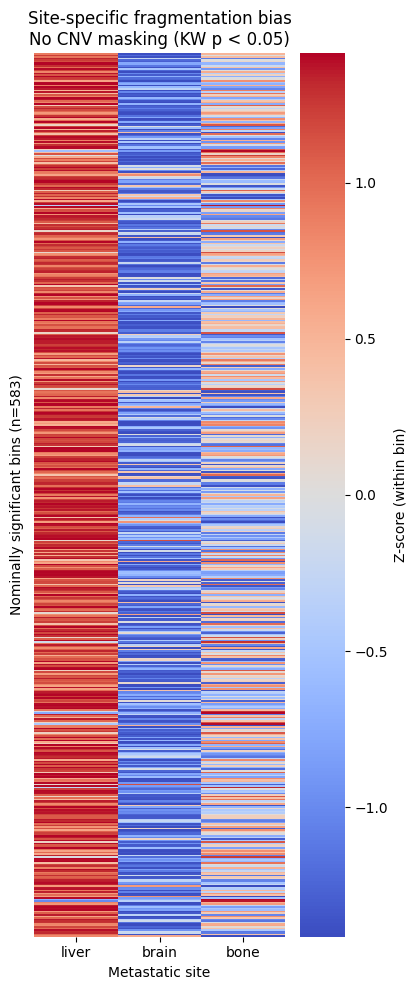

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/Heatmap_noCNV_top1000_raw.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/Heatmap_noCNV_top1000_raw.pdf


In [15]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# Settings
# -----------------------------
FILTER_MODE = "raw"   # choose from: "raw", "bh", "all"

INFILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/"
    "Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/"
    "Effect_size_no_cnv_masking/KW_BH/"
    "KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"
)

OUTDIR = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/"
    "Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/"
    "Effect_size_no_cnv_masking/KW_BH"
)
os.makedirs(OUTDIR, exist_ok=True)

OUTPNG = os.path.join(OUTDIR, f"Heatmap_noCNV_top1000_{FILTER_MODE}.png")
OUTPDF = os.path.join(OUTDIR, f"Heatmap_noCNV_top1000_{FILTER_MODE}.pdf")

# -----------------------------
# Load final annotated file
# -----------------------------
df = pd.read_csv(INFILE, sep="\t")

# -----------------------------
# Filter bins
# -----------------------------
if FILTER_MODE == "raw":
    df = df[df["kw_p"] < 0.05].copy()
    ylab = f"Nominally significant bins (n={df.shape[0]})"
    title = "Site-specific fragmentation bias\nNo CNV masking (KW p < 0.05)"
elif FILTER_MODE == "bh":
    df = df[df["kw_q_BH"] < 0.05].copy()
    ylab = f"BH-significant bins (n={df.shape[0]})"
    title = "Site-specific fragmentation bias\nNo CNV masking (BH-FDR < 0.05)"
elif FILTER_MODE == "all":
    df = df.copy()
    ylab = f"Top 1000 bins ranked by η² (n={df.shape[0]})"
    title = "Site-specific fragmentation bias\nNo CNV masking (Top 1000 η²-ranked bins)"
else:
    raise ValueError("FILTER_MODE must be one of: 'raw', 'bh', 'all'")

print("Bins retained after filtering:", df.shape[0])

# -----------------------------
# Keep bins ordered by effect size
# -----------------------------
df = df.sort_values("rank_eta2").copy()

# -----------------------------
# Site-wise median matrix
# -----------------------------
mat = df[["median_liver", "median_brain", "median_bone"]].to_numpy(dtype=float)

# -----------------------------
# Z-score across sites per bin
# -----------------------------
row_means = mat.mean(axis=1, keepdims=True)
row_stds  = mat.std(axis=1, keepdims=True)

# avoid divide-by-zero
row_stds[row_stds == 0] = 1

mat_z = (mat - row_means) / row_stds

mat_z = pd.DataFrame(
    mat_z,
    index=df["bin_id"],
    columns=["liver", "brain", "bone"]
)

# -----------------------------
# Plot heatmap
# -----------------------------
plt.figure(figsize=(4.2, 10))

sns.heatmap(
    mat_z,
    cmap="coolwarm",
    center=0,
    yticklabels=False,
    xticklabels=True,
    cbar_kws={"label": "Z-score (within bin)"}
)

plt.xlabel("Metastatic site")
plt.ylabel(ylab)
plt.title(title)

plt.tight_layout()

# save before show
plt.savefig(OUTPNG, dpi=300, bbox_inches="tight")
plt.savefig(OUTPDF, bbox_inches="tight")

plt.show()
plt.close()

print("Saved:")
print(OUTPNG)
print(OUTPDF)

Bins after raw KW p<0.05 filter: 583


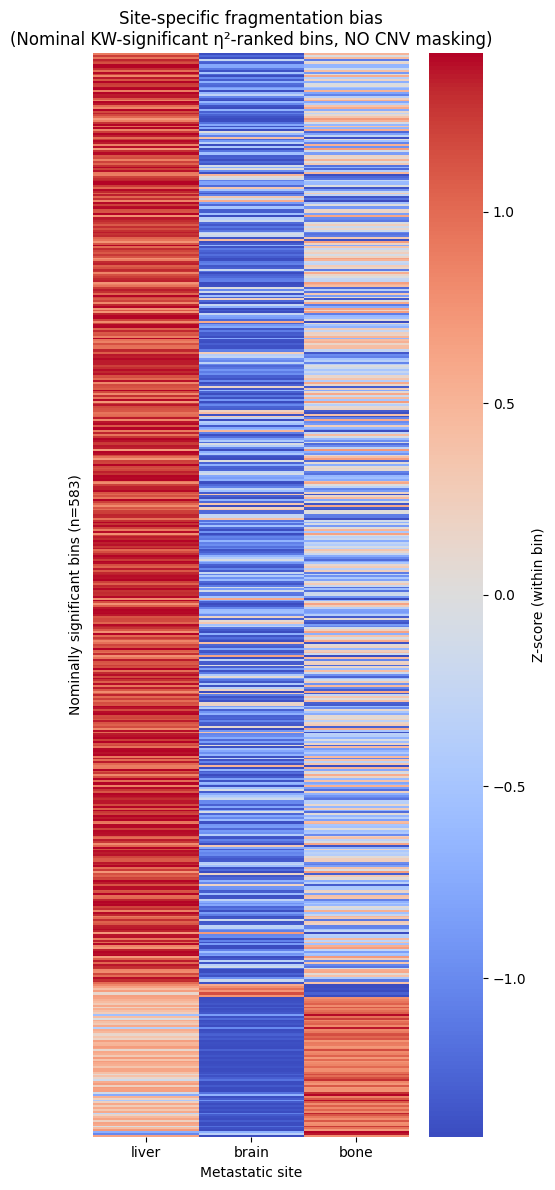

Saved heatmap:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/heatmap.no_cnv_masking.top1000.site_grouped_raw.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/heatmap.no_cnv_masking.top1000.site_grouped_raw.pdf


In [16]:
# Heatmap of nominally significant bins (NO CNV Masking)
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------
# Settings
# -------------------------
FILTER_MODE = "raw"   # options: "raw", "bh", "all"

# -------------------------
# Paths (NO CNV masking)
# -------------------------
INFILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"
)

OUTDIR = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH"
)

os.makedirs(OUTDIR, exist_ok=True)

OUTPNG = os.path.join(OUTDIR, f"heatmap.no_cnv_masking.top1000.site_grouped_{FILTER_MODE}.png")
OUTPDF = os.path.join(OUTDIR, f"heatmap.no_cnv_masking.top1000.site_grouped_{FILTER_MODE}.pdf")

# -------------------------
# Load data
# -------------------------
df = pd.read_csv(INFILE, sep="\t")

# -------------------------
# Filter bins
# -------------------------
if FILTER_MODE == "raw":
    df = df[df["kw_p"] < 0.05].copy()
    print("Bins after raw KW p<0.05 filter:", df.shape[0])
    ylab = f"Nominally significant bins (n={df.shape[0]})"
    title = "Site-specific fragmentation bias\n(Nominal KW-significant η²-ranked bins, NO CNV masking)"
elif FILTER_MODE == "bh":
    df = df[df["kw_q_BH"] < 0.05].copy()
    print("Bins after BH q<0.05 filter:", df.shape[0])
    ylab = f"BH-significant bins (n={df.shape[0]})"
    title = "Site-specific fragmentation bias\n(BH-significant η²-ranked bins, NO CNV masking)"
elif FILTER_MODE == "all":
    df = df.copy()
    print("Using all top1000 η²-ranked bins:", df.shape[0])
    ylab = f"Top η²-ranked bins (n={df.shape[0]})"
    title = "Site-specific fragmentation bias\n(Top 1000 η²-ranked bins, NO CNV masking)"
else:
    raise ValueError("FILTER_MODE must be one of: 'raw', 'bh', or 'all'")

# -------------------------
# Order within site groups by effect size
# -------------------------
site_order = ["liver", "brain", "bone"]

df["site_highest"] = pd.Categorical(
    df["site_highest"],
    categories=site_order,
    ordered=True
)

df = df.sort_values(["site_highest", "rank_eta2"]).copy()

# -------------------------
# Build median matrix
# -------------------------
mat = df[["median_liver", "median_brain", "median_bone"]].to_numpy(dtype=float)

# -------------------------
# Row-wise Z-score (within bin)
# -------------------------
row_means = mat.mean(axis=1, keepdims=True)
row_stds  = mat.std(axis=1, keepdims=True)
row_stds[row_stds == 0] = 1  # avoid divide-by-zero

mat_z = (mat - row_means) / row_stds

mat_z = pd.DataFrame(
    mat_z,
    index=df["bin_id"],
    columns=["liver", "brain", "bone"]
)

# -------------------------
# Plot heatmap
# -------------------------
plt.figure(figsize=(5, 12))

sns.heatmap(
    mat_z,
    cmap="coolwarm",
    center=0,
    yticklabels=False,
    xticklabels=True,
    cbar_kws={"label": "Z-score (within bin)"}
)

plt.xlabel("Metastatic site")
plt.ylabel(ylab)
plt.title(title)

plt.tight_layout()

plt.savefig(OUTPNG, dpi=300, bbox_inches="tight")
plt.savefig(OUTPDF, bbox_inches="tight")
plt.show()
plt.close()

print("Saved heatmap:")
print(OUTPNG)
print(OUTPDF)

In [18]:
import pandas as pd
import numpy as np

# -------------------------
# Settings
# -------------------------
FILTER_MODE = "raw"   # options: "raw", "bh", "all"

# -------------------------
# Paths (NO CNV masking)
# -------------------------
BINS_TSV = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"
)

CYTOBAND = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Human_ref_hg38_p7/cytoBand.txt"

OUT_TSV = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    f"KW_BH/KW_BH.no_cnv_masking.{FILTER_MODE}sig.with_site_direction.with_chrarm.tsv"
)

# -------------------------
# Load bins + filter
# -------------------------
df = pd.read_csv(BINS_TSV, sep="\t", dtype={"bin_id": str})

if FILTER_MODE == "raw":
    df_sig = df[df["kw_p"] < 0.05].copy()
    print("Total nominally significant bins (raw KW p < 0.05):", df_sig.shape[0])
elif FILTER_MODE == "bh":
    df_sig = df[df["kw_q_BH"] < 0.05].copy()
    print("Total BH-significant bins (q < 0.05):", df_sig.shape[0])
elif FILTER_MODE == "all":
    df_sig = df.copy()
    print("Using all top1000 η²-ranked bins:", df_sig.shape[0])
else:
    raise ValueError("FILTER_MODE must be one of: 'raw', 'bh', or 'all'")

# Parse bin_id: chr3_171800000_171900000
parts = df_sig["bin_id"].astype(str).str.split("_", expand=True)
df_sig["chrom"] = parts.iloc[:, 0].astype(str).str.strip()
df_sig["start"] = parts.iloc[:, 1].astype(int)
df_sig["end"]   = parts.iloc[:, 2].astype(int)
df_sig["mid"]   = ((df_sig["start"] + df_sig["end"]) // 2).astype(int)

# -------------------------
# Load cytoband
# -------------------------
cyto = pd.read_csv(
    CYTOBAND,
    sep="\t",
    header=None,
    names=["chrom", "start", "end", "band", "stain"]
)
cyto["chrom"] = cyto["chrom"].astype(str).str.strip()
cyto["arm"] = cyto["band"].astype(str).str[0]
cyto = cyto[cyto["arm"].isin(["p", "q"])].copy()

# Pre-split cytoband dict
cyto_by_chr = {
    c: d.sort_values("start").reset_index(drop=True)
    for c, d in cyto.groupby("chrom")
}

# -------------------------
# Chromosome-wise merge_asof
# -------------------------
out_chunks = []

for chrom, sub in df_sig.groupby("chrom", sort=False):
    sub = sub.sort_values("mid").reset_index(drop=True)

    cb = cyto_by_chr.get(chrom)
    if cb is None or cb.shape[0] == 0:
        sub["arm"] = np.nan
        sub["band"] = np.nan
        sub["chrom_arm"] = np.nan
        out_chunks.append(sub)
        continue

    cb2 = cb[["start", "end", "arm", "band"]].rename(
        columns={"start": "cb_start", "end": "cb_end"}
    ).copy()
    cb2 = cb2.sort_values("cb_start").reset_index(drop=True)

    annot = pd.merge_asof(
        sub,
        cb2,
        left_on="mid",
        right_on="cb_start",
        direction="backward",
        allow_exact_matches=True
    )

    # verify midpoint lies within interval
    in_interval = (annot["mid"] >= annot["cb_start"]) & (annot["mid"] < annot["cb_end"])
    annot.loc[~in_interval, ["arm", "band"]] = np.nan

    annot["chrom_arm"] = np.where(
        annot["arm"].isna(),
        np.nan,
        annot["chrom"] + annot["arm"].astype(str)
    )

    out_chunks.append(annot)

annot_all = pd.concat(out_chunks, ignore_index=True)

# Optional
# annot_all.drop(columns=["mid", "cb_start", "cb_end"], inplace=True, errors="ignore")

annot_all.to_csv(OUT_TSV, sep="\t", index=False)
print("Wrote:", OUT_TSV)

print("chrom_arm counts (top):")
print(annot_all["chrom_arm"].value_counts(dropna=False).head(20))

Total nominally significant bins (raw KW p < 0.05): 583
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.rawsig.with_site_direction.with_chrarm.tsv
chrom_arm counts (top):
chr4q     32
chr2q     31
chr12q    28
chr8q     27
chr11q    26
chr7q     26
chr5q     25
chr14q    24
chr6q     22
chr1q     21
chr6p     20
chr3p     19
chr10q    18
chr18q    18
chr1p     16
chr3q     16
chr11p    15
chr9q     15
chr17q    14
chr13q    14
Name: chrom_arm, dtype: int64


In [19]:
# Step 9 (NO CNV masking): Make a BED for significant bins for gene-level annotation

import pandas as pd

# -------------------------
# Settings
# -------------------------
FILTER_MODE = "raw"   # options: "raw", "bh", "all"

# -------------------------
# Paths
# -------------------------
INFILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"
)

OUT_BED = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    f"KW_BH/no_cnv_masking.{FILTER_MODE}sig.bins.bed"
)

# -------------------------
# Load + filter
# -------------------------
df = pd.read_csv(INFILE, sep="\t", dtype={"bin_id": str})

if FILTER_MODE == "raw":
    df = df[df["kw_p"] < 0.05].copy()
    print("Using nominally significant bins (raw KW p < 0.05):", df.shape[0])
elif FILTER_MODE == "bh":
    df = df[df["kw_q_BH"] < 0.05].copy()
    print("Using BH-significant bins (q < 0.05):", df.shape[0])
elif FILTER_MODE == "all":
    df = df.copy()
    print("Using all top1000 η²-ranked bins:", df.shape[0])
else:
    raise ValueError("FILTER_MODE must be one of: 'raw', 'bh', or 'all'")

# -------------------------
# Parse bin_id
# -------------------------
parts = df["bin_id"].astype(str).str.split("_", expand=True)
df["chr"] = parts.iloc[:, 0]
df["start"] = parts.iloc[:, 1].astype(int)
df["end"] = parts.iloc[:, 2].astype(int)

# 4th column = bin_id (so we can map back later)
bed = df[["chr", "start", "end", "bin_id"]].drop_duplicates()
bed.to_csv(OUT_BED, sep="\t", header=False, index=False)

print("Wrote:", OUT_BED, "n =", bed.shape[0])

Using nominally significant bins (raw KW p < 0.05): 583
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/no_cnv_masking.rawsig.bins.bed n = 583


In [2]:
# B) Intersect bins with genes (By using Bedtool)
# C) Collapse genes per bin_id + merge back into your TSV (NO CNV masking)

import os
import pandas as pd

# -------------------------
# Settings
# -------------------------
FILTER_MODE = "raw"   # options: "raw", "bh", "all"

# -------------------------
# Paths
# -------------------------
IN_TSV = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"
)

HITS = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    f"KW_BH/no_cnv_masking.{FILTER_MODE}sig.bins.geneHits.tsv"
)

OUT_TSV = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    f"KW_BH/KW_BH.no_cnv_masking.{FILTER_MODE}sig.with_site_direction.with_genes.tsv"
)

# -------------------------
# Load + filter bins
# -------------------------
df = pd.read_csv(IN_TSV, sep="\t", dtype={"bin_id": str})

if FILTER_MODE == "raw":
    df_sig = df[df["kw_p"] < 0.05].copy()
    print("Using nominally significant bins (raw KW p < 0.05):", df_sig.shape[0])
elif FILTER_MODE == "bh":
    df_sig = df[df["kw_q_BH"] < 0.05].copy()
    print("Using BH-significant bins (q < 0.05):", df_sig.shape[0])
elif FILTER_MODE == "all":
    df_sig = df.copy()
    print("Using all top1000 η²-ranked bins:", df_sig.shape[0])
else:
    raise ValueError("FILTER_MODE must be one of: 'raw', 'bh', or 'all'")

# -------------------------
# If no bins, still write an empty output cleanly
# -------------------------
if df_sig.empty:
    df_sig["genes"] = ""
    df_sig.to_csv(OUT_TSV, sep="\t", index=False)
    print("No bins passed filter. Wrote empty annotated file:", OUT_TSV)
else:
    # -------------------------
    # Read bedtools intersect output
    # -------------------------
    if (not os.path.exists(HITS)) or os.path.getsize(HITS) == 0:
        print("geneHits file missing or empty; writing bins with blank gene annotations.")
        df_sig["genes"] = ""
        df_sig.to_csv(OUT_TSV, sep="\t", index=False)
        print("Wrote:", OUT_TSV, "rows:", df_sig.shape[0])
    else:
        hits = pd.read_csv(HITS, sep="\t", header=None)

        # columns: bins (0-3) + genes (4..)
        # Typical gene BED: chr start end gene_name ensg
        BIN_ID_COL = 3
        GENE_NAME_COL = 7   # adjust only if your gene BED structure differs

        hits = hits[[BIN_ID_COL, GENE_NAME_COL]].rename(
            columns={BIN_ID_COL: "bin_id", GENE_NAME_COL: "gene_name"}
        )
        hits["bin_id"] = hits["bin_id"].astype(str).str.strip()
        hits["gene_name"] = hits["gene_name"].astype(str).str.strip()

        # remove blanks / NA-like strings
        hits = hits[
            hits["gene_name"].notna() &
            (~hits["gene_name"].isin(["", "nan", "None", "."]))
        ].copy()

        # collapse unique gene names per bin
        gene_map = (
            hits.groupby("bin_id")["gene_name"]
                .apply(lambda x: ",".join(sorted(set(x))))
                .reset_index()
                .rename(columns={"gene_name": "genes"})
        )

        # merge back; bins with no overlaps get empty string
        df_sig = df_sig.merge(gene_map, on="bin_id", how="left")
        df_sig["genes"] = df_sig["genes"].fillna("")

        df_sig.to_csv(OUT_TSV, sep="\t", index=False)
        print("Wrote:", OUT_TSV, "rows:", df_sig.shape[0])

Using nominally significant bins (raw KW p < 0.05): 583
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.rawsig.with_site_direction.with_genes.tsv rows: 583


In [21]:
# Generate BED files for LOLA (NO CNV masking)

import os
import pandas as pd

# -------------------------
# Settings
# -------------------------
FILTER_MODE = "raw"   # options: "raw", "bh", "all"

# -------------------------
# INPUT
# -------------------------
INFILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"
)

# -------------------------
# OUTPUT DIR
# -------------------------
OUTDIR = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH"
)
os.makedirs(OUTDIR, exist_ok=True)

TOP_N = 1000
SITES = ["liver", "brain", "bone"]

# -------------------------
# Convert bin_id like chr3_171800000_171900000 -> BED columns
# -------------------------
def bin_id_to_bed(df, bin_col="bin_id"):
    if df.empty:
        return pd.DataFrame(columns=["chr", "start", "end"])

    parts = df[bin_col].astype(str).str.split("_", expand=True)
    if parts.shape[1] < 3:
        return pd.DataFrame(columns=["chr", "start", "end"])

    out = pd.DataFrame({
        "chr": parts.iloc[:, 0],
        "start": pd.to_numeric(parts.iloc[:, 1], errors="coerce"),
        "end": pd.to_numeric(parts.iloc[:, 2], errors="coerce"),
    }).dropna(subset=["chr", "start", "end"]).copy()

    out["start"] = out["start"].astype(int)
    out["end"] = out["end"].astype(int)
    return out

# -------------------------
# Load + filter
# -------------------------
df = pd.read_csv(INFILE, sep="\t", dtype={"bin_id": str})

if FILTER_MODE == "raw":
    df = df[df["kw_p"] < 0.05].copy()
    print("Using nominally significant bins (raw KW p < 0.05):", df.shape[0])
elif FILTER_MODE == "bh":
    df = df[df["kw_q_BH"] < 0.05].copy()
    print("Using BH-significant bins (q < 0.05):", df.shape[0])
elif FILTER_MODE == "all":
    df = df.copy()
    print("Using all top1000 η²-ranked bins:", df.shape[0])
else:
    raise ValueError("FILTER_MODE must be one of: 'raw', 'bh', or 'all'")

# -------------------------
# Write per-site BEDs
# -------------------------
for site in SITES:
    sub = df[df["site_highest"] == site].copy()

    if sub.empty:
        print(f"SKIP {site}: no bins after filtering")
        continue

    sub = sub.drop_duplicates(subset=["bin_id"])
    bed = bin_id_to_bed(sub)

    if bed.empty:
        print(f"SKIP {site}: no valid BED rows after bin_id parsing")
        continue

    out_bed = os.path.join(
        OUTDIR,
        f"no_cnv_masking.{FILTER_MODE}sig.top{TOP_N}.{site}_high.bed"
    )

    bed.to_csv(out_bed, sep="\t", header=False, index=False)

    print(f"Wrote {site}_high: {out_bed}  (n={bed.shape[0]})")

Using nominally significant bins (raw KW p < 0.05): 583
Wrote liver_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/no_cnv_masking.rawsig.top1000.liver_high.bed  (n=502)
Wrote brain_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/no_cnv_masking.rawsig.top1000.brain_high.bed  (n=6)
Wrote bone_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/no_cnv_masking.rawsig.top1000.bone_high.bed  (n=75)


Nominally significant bins (raw KW p < 0.05): 583
Bins found in ratio matrix (autosomes): 583
Using TOP3 sites only: ['liver', 'bone', 'brain']
Samples with meta: 50
Bins with arm assigned: 583


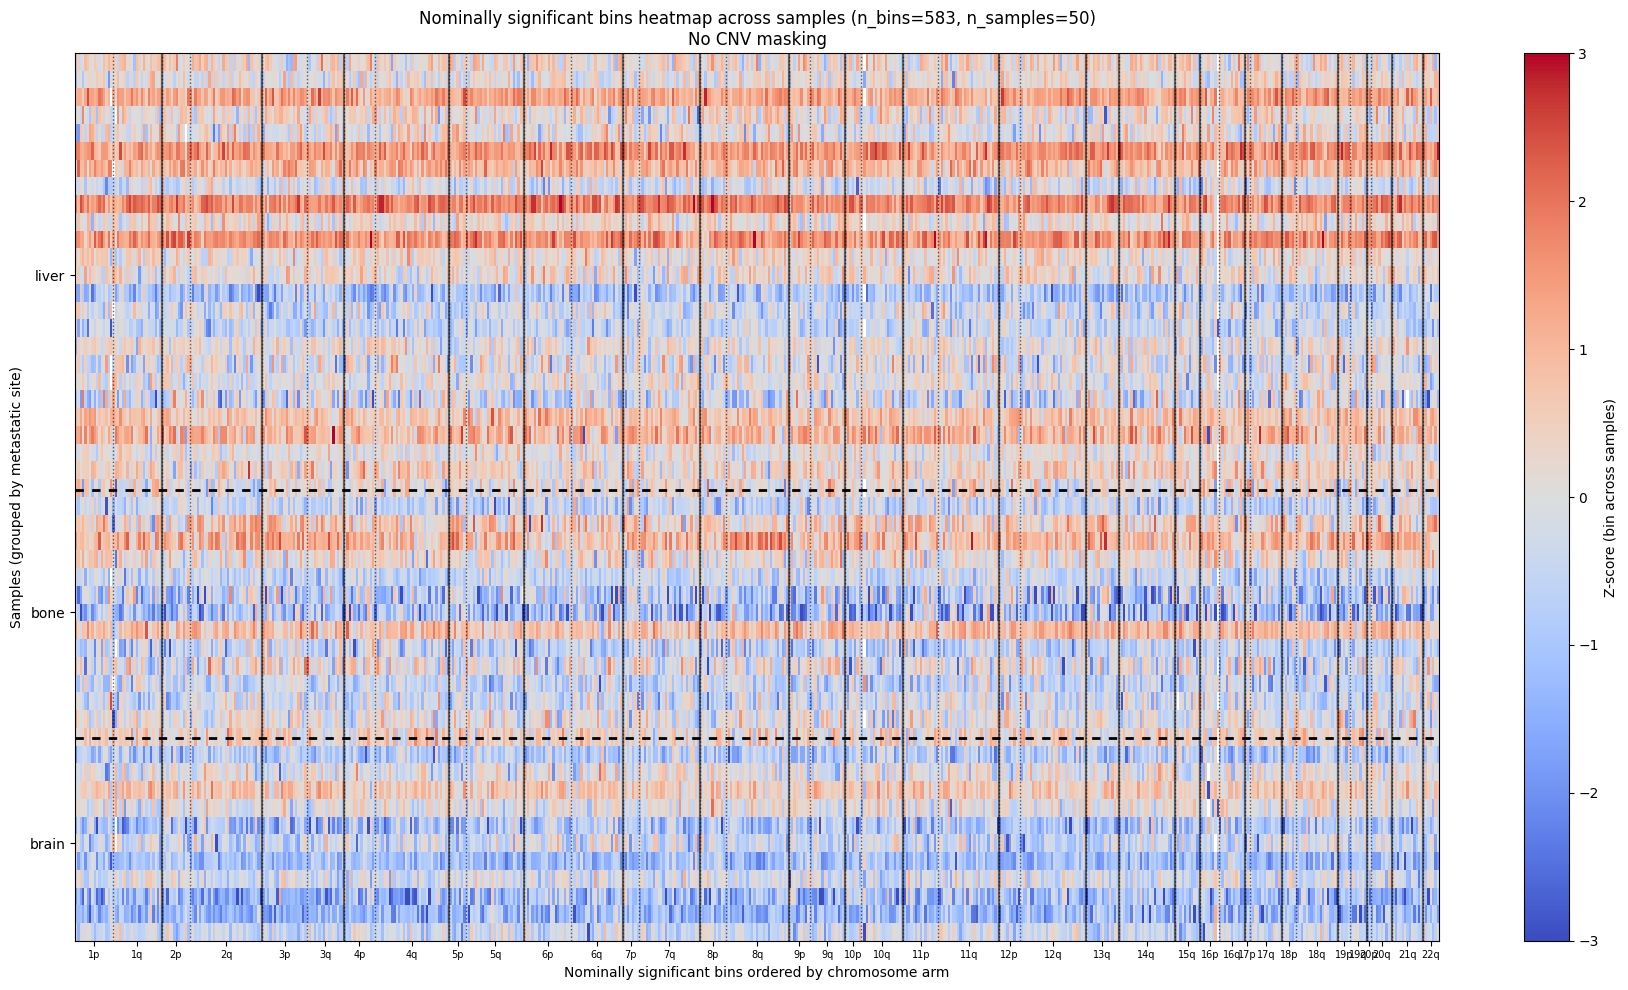

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/rawsig_bins_allSamples_armOrdered_heatmap/heatmap.rawsig.allSamples.chrArmOrdered.no_cnv_masking.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/rawsig_bins_allSamples_armOrdered_heatmap/heatmap.rawsig.allSamples.chrArmOrdered.no_cnv_masking.pdf


In [1]:
# Heatmap: filtered bins across ALL samples (NO CNV masking)
# X-axis: chr + arm (p/q) ordered; Y-axis: samples grouped by metastatic site

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Settings
# -----------------------------
FILTER_MODE = "raw"   # options: "raw", "bh", "all"

# -----------------------------
# Inputs (NO CNV masking)
# -----------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"

BINS_TSV = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    "KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"
)

META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

CYTOBAND = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Human_ref_hg38_p7/cytoBand.txt"

OUTDIR = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/"
    "Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/"
    f"KW_BH/{FILTER_MODE}sig_bins_allSamples_armOrdered_heatmap"
)
os.makedirs(OUTDIR, exist_ok=True)

OUTPNG = os.path.join(OUTDIR, f"heatmap.{FILTER_MODE}sig.allSamples.chrArmOrdered.no_cnv_masking.png")
OUTPDF = os.path.join(OUTDIR, f"heatmap.{FILTER_MODE}sig.allSamples.chrArmOrdered.no_cnv_masking.pdf")

# -----------------------------
# Options
# -----------------------------
LOG2_TRANSFORM = True
Z_SCORE_PER_BIN = True
CLIP_VMIN, CLIP_VMAX = (-3, 3)
FIGSIZE = (18, 10)

TOP3_ONLY = True

# -----------------------------
# Helpers
# -----------------------------
CHR_ORDER = [f"chr{i}" for i in range(1, 23)]

def parse_bin(bin_id: str):
    chrom, start, end = bin_id.split("_")
    return chrom, int(start), int(end)

def load_cytoband(cyto_path):
    cb = pd.read_csv(
        cyto_path,
        sep="\t",
        header=None,
        names=["chrom", "start", "end", "band", "stain"],
        dtype={"chrom": str, "start": int, "end": int, "band": str, "stain": str}
    )
    cb = cb[cb["chrom"].isin(CHR_ORDER)].copy()
    cb["arm"] = cb["band"].str[0]
    return cb

def assign_arm_to_bin(bin_id, cytoband_df):
    chrom, start, end = parse_bin(bin_id)
    if chrom not in CHR_ORDER:
        return None
    mid = (start + end) // 2
    hits = cytoband_df[
        (cytoband_df["chrom"] == chrom) &
        (cytoband_df["start"] <= mid) &
        (cytoband_df["end"] >= mid)
    ]
    if hits.shape[0] == 0:
        return None
    arm = hits.iloc[0]["arm"]
    if arm not in ("p", "q"):
        return None
    return arm

def zscore_by_bin_across_samples(df):
    mu = df.mean(axis=0, skipna=True)
    sd = df.std(axis=0, skipna=True).replace(0, np.nan)
    return (df - mu) / sd

def compute_site_order(meta_series):
    return meta_series.value_counts().index.tolist()

# -----------------------------
# Load ratio matrix
# -----------------------------
ratio = pd.read_csv(RATIO_FILE, index_col=0)
ratio.index = ratio.index.astype(str).str.strip()
ratio.index.name = "sample"

# Drop duplicate sample IDs if any
dup_ratio = ratio.index.duplicated(keep="first")
if dup_ratio.sum() > 0:
    print(f"[WARN] Dropping {int(dup_ratio.sum())} duplicated sample rows from ratio matrix")
    ratio = ratio.loc[~dup_ratio].copy()

if LOG2_TRANSFORM:
    ratio = np.log2(ratio.replace(0, np.nan))

# -----------------------------
# Load filtered bins list
# -----------------------------
df = pd.read_csv(BINS_TSV, sep="\t", dtype={"bin_id": str})

if FILTER_MODE == "raw":
    df = df[df["kw_p"] < 0.05].copy()
    print("Nominally significant bins (raw KW p < 0.05):", df.shape[0])
elif FILTER_MODE == "bh":
    df = df[df["kw_q_BH"] < 0.05].copy()
    print("BH-significant bins (q < 0.05):", df.shape[0])
elif FILTER_MODE == "all":
    df = df.copy()
    print("Using all top1000 bins:", df.shape[0])
else:
    raise ValueError("FILTER_MODE must be one of: 'raw', 'bh', 'all'")

sig_bins = df["bin_id"].astype(str).tolist()

# Keep only bins present in ratio columns + autosomes
sig_bins = [b for b in sig_bins if b in ratio.columns and b.split("_")[0] in CHR_ORDER]
print("Bins found in ratio matrix (autosomes):", len(sig_bins))

# -----------------------------
# Load meta + match samples
# -----------------------------
meta = pd.read_csv(META_FILE, dtype=str)
meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()

# Drop duplicate sample IDs if any
dup_meta = meta["id"].duplicated(keep="first")
if dup_meta.sum() > 0:
    print(f"[WARN] Dropping {int(dup_meta.sum())} duplicated sample rows from metadata")
    meta = meta.loc[~dup_meta].copy()

meta = meta[meta["id"].isin(ratio.index)].copy()
meta = meta.set_index("id")

if TOP3_ONLY:
    top3 = meta["metastatic_sites"].value_counts().head(3).index.tolist()
    meta = meta[meta["metastatic_sites"].isin(top3)].copy()
    print("Using TOP3 sites only:", top3)

ratio2 = ratio.loc[meta.index].copy()
print("Samples with meta:", ratio2.shape[0])

# -----------------------------
# Cytoband: assign chr arm to each bin
# -----------------------------
cyto = load_cytoband(CYTOBAND)

bin_rows = []
for b in sig_bins:
    chrom, start, end = parse_bin(b)
    arm = assign_arm_to_bin(b, cyto)
    if arm is None:
        continue
    chrom_num = int(chrom.replace("chr", ""))
    bin_rows.append((b, chrom, chrom_num, arm, start, end))

bin_annot = pd.DataFrame(
    bin_rows,
    columns=["bin_id", "chrom", "chrom_num", "arm", "start", "end"]
)
print("Bins with arm assigned:", bin_annot.shape[0])

if bin_annot.empty:
    raise ValueError("No bins available after filtering and cytoband arm assignment.")

arm_order = {"p": 0, "q": 1}
bin_annot["arm_rank"] = bin_annot["arm"].map(arm_order).astype(int)
bin_annot = bin_annot.sort_values(["chrom_num", "arm_rank", "start"]).reset_index(drop=True)

ordered_bins = bin_annot["bin_id"].tolist()

# -----------------------------
# Build heatmap matrix
# -----------------------------
X = ratio2[ordered_bins].copy()

if Z_SCORE_PER_BIN:
    X = zscore_by_bin_across_samples(X)

# -----------------------------
# Order samples by metastatic site
# -----------------------------
site_order = compute_site_order(meta["metastatic_sites"])
meta_ord = meta.copy()
meta_ord["metastatic_sites"] = pd.Categorical(
    meta_ord["metastatic_sites"],
    categories=site_order,
    ordered=True
)
meta_ord = meta_ord.sort_values(["metastatic_sites"])

X = X.loc[meta_ord.index]

site_sizes = (
    meta_ord["metastatic_sites"]
    .value_counts()
    .reindex(site_order)
    .fillna(0)
    .astype(int)
)
y_boundaries = np.cumsum(site_sizes.values)[:-1]

yticks, ylabels = [], []
start = 0
for site in site_order:
    n = int((meta_ord["metastatic_sites"] == site).sum())
    if n > 0:
        yticks.append(start + n / 2)
        ylabels.append(site)
        start += n

# -----------------------------
# X boundaries: arm changes + chr changes
# -----------------------------
arm_keys = list(zip(bin_annot["chrom"].tolist(), bin_annot["arm"].tolist()))
x_boundaries = []
chr_boundaries = []

if len(arm_keys) > 0:
    prev = arm_keys[0]
    prev_chr = bin_annot.loc[0, "chrom"]

    for i in range(1, len(arm_keys)):
        if arm_keys[i] != prev:
            x_boundaries.append(i - 0.5)
            prev = arm_keys[i]
        if bin_annot.loc[i, "chrom"] != prev_chr:
            chr_boundaries.append(i - 0.5)
            prev_chr = bin_annot.loc[i, "chrom"]

blocks = []
if len(arm_keys) > 0:
    block_start = 0
    for i in range(1, len(arm_keys) + 1):
        if i == len(arm_keys) or arm_keys[i] != arm_keys[i - 1]:
            chrom, arm = arm_keys[i - 1]
            blocks.append((chrom, arm, block_start, i - 1))
            block_start = i

xticks = [(s + e) / 2 for (_, _, s, e) in blocks]
xlabels = [f"{c.replace('chr','')}{a}" for (c, a, _, _) in blocks]

# -----------------------------
# Labels
# -----------------------------
if FILTER_MODE == "raw":
    xlabel = "Nominally significant bins ordered by chromosome arm"
    title = f"Nominally significant bins heatmap across samples (n_bins={X.shape[1]}, n_samples={X.shape[0]})\nNo CNV masking"
elif FILTER_MODE == "bh":
    xlabel = "BH-significant bins ordered by chromosome arm"
    title = f"BH-significant bins heatmap across samples (n_bins={X.shape[1]}, n_samples={X.shape[0]})\nNo CNV masking"
else:
    xlabel = "Top η²-ranked bins ordered by chromosome arm"
    title = f"Top η²-ranked bins heatmap across samples (n_bins={X.shape[1]}, n_samples={X.shape[0]})\nNo CNV masking"

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=FIGSIZE)
plt.imshow(
    X.values,
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=CLIP_VMIN,
    vmax=CLIP_VMAX
)

cbar_label = "Z-score (bin across samples)" if Z_SCORE_PER_BIN else ("log2(short/long)" if LOG2_TRANSFORM else "short/long")
plt.colorbar(label=cbar_label)

for b in y_boundaries:
    plt.axhline(b + 0.1, color="black", linewidth=2.0, linestyle=(0, (3, 3)))

for xb in x_boundaries:
    plt.axvline(xb, color="black", linewidth=1.0, linestyle=":", alpha=0.6)

for xb in chr_boundaries:
    plt.axvline(xb, color="black", linewidth=1.6, linestyle="-", alpha=0.55)

plt.yticks(yticks, ylabels)
plt.xticks(xticks, xlabels, fontsize=7, rotation=0)

plt.xlabel(xlabel)
plt.ylabel("Samples (grouped by metastatic site)")
plt.title(title)

plt.tight_layout()
plt.savefig(OUTPNG, dpi=300, bbox_inches="tight")
plt.savefig(OUTPDF, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:")
print(OUTPNG)
print(OUTPDF)